# Uganda healthcare electrification: a fresh EAE analysis

**Case Study 4 | USD 1,000,000 | 9 November 2026**

All geospatial inputs were downloaded from the live Energy Access Explorer catalogue and its linked public storage. No previous local exports, notebook, report or generated tables are analytical inputs. The assignment and lecture supplied the brief only. The Ministry of Health project announcement is the sole external cost comparator.

The decision is how to combine concentrated unserved healthcare need with support for more expensive remote facilities. The four-page report is in `report/case_study_4_report.pdf`. This notebook exposes the reproducible calculations and their limits.

## 1. Sources and environment

Install `requirements.txt`, start Jupyter from the repository, and run all cells. The pipeline modules contain the complete implementation; the notebook executes them and shows the saved evidence. Network access is required only to refresh downloads or install dependencies. The saved analysis is reproducible offline. UTC retrieval dates, URLs and SHA-256 hashes are retained in the manifest.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT/'config.json').exists():
    ROOT = ROOT.parent
assert (ROOT/'config.json').exists(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT))
manifest = pd.read_json(ROOT/'data/download_manifest.jsonl', lines=True)
display(manifest[['file','retrieved_utc','bytes','sha256']])
config = json.loads((ROOT/'config.json').read_text())
display(config)

,file,retrieved_utc,bytes,sha256
0,data/raw/uganda-geographies.json,2026-11-08T21:39:52.322986+00:00,1785,31db2ab953989c96b6dfa423519b8018b5c213f39bafd8...
1,data/raw/uganda-datasets.json,2026-11-08T21:40:15.626437+00:00,236400,dfedd6d0e247d6ed1c7e733e0022cc0719cd977de20b7b...
2,data/raw/health-facilities.geojson,2026-11-08T21:41:04.005324+00:00,4322284,7d79fb130233b51b874b24e297a5d4495f335a455fa95e...
3,data/raw/districts.geojson,2026-11-08T21:41:06.507575+00:00,2835228,76b665fd0f1263411886fd0771946bf19f2252781996c6...
4,data/raw/distribution-distance.tif,2026-11-08T21:41:08.338782+00:00,776883,562f92db4900867c4fc98209e2c89b18fd3e2fe4364349...
5,data/raw/wealth.tif,2026-11-08T21:41:10.140787+00:00,635291,132eba7c5d0bd639133da445250a43afdbbaa4f878d6d1...
6,data/raw/solar-ghi.tif,2026-11-08T21:41:12.462500+00:00,2354099,11e67b12654cb26e936054ebed9e75dd32a5eb4fa1b31b...
7,data/raw/population.tif,2026-11-08T21:41:14.776839+00:00,1447114,d42326afcf159fdf747b033d602c109c621c73e9a86ea8...
8,data/raw/selected-categories.json,2026-11-08T21:42:59.904239+00:00,9176,c85b5e87e18a997bc00ea5b55bbe83fc7f65812ead23f0...


{'budget_usd': 1000000,
 'installation_budget_usd': 800000,
 'audit_usd': 50000,
 'five_year_maintenance_usd': 100000,
 'minimum_contingency_usd': 50000,
 'hc_ii_critical_system_usd': 20000,
 'hc_iii_critical_system_usd': 40000,
 'remote_distance_km': 5,
 'remote_cost_multiplier': 1.25,
 'catchment_radius_km': 5,
 'distance_score_cap_km': 10,
 'weights': {'population': 0.45,
  'clinical_energy': 0.25,
  'distance': 0.2,
  'poverty': 0.1},
 'districts_to_fund': 5,
 'maximum_facilities_per_district': 10,
 'minimum_remote_installation_share': 0.3}

## 2. Re-run the complete spatial analysis

The source inventory has 4,938 facilities. Match them geometrically to 2024 districts. Keep government HC II/HC III records with both electricity fields equal to `No`, excluding ERT-flagged sites. All other records remain in the audit. The older electricity-status data require field verification before awards. Off-grid is not equivalent to unelectrified.

Population is allocated to the nearest facility among **all** facilities, including private and electrified alternatives. Cells are counted once; co-located facilities share the assigned population. Distances are measured from 1 km cell centres in EPSG:3857 at radii of 3, 5 and 10 km. This approximates geographic access, not patient choice or walking time. The categorical `Catch_pop` values are not summed as unique people.

In [2]:
from src.analyse import run
summary = run()
display(pd.Series(summary, name='Result'))
display(pd.read_json(ROOT/'outputs/catchment_audit.json', typ='series'))

{
  "data_source": "Fresh live EAE API and EAE-linked public storage; no previous local exports",
  "source_facilities": 4938,
  "source_electricity_status": {
    "On-grid": 2673,
    "Off-grid": 1553,
    "No": 582,
    "Data unavailable": 130
  },
  "public_unserved_hc_ii_iii_before_exclusions": 529,
  "eligible_facilities": 527,
  "eligible_districts": 104,
  "ert_flagged_in_base_filter": 2,
  "base_filter_boundary_unmatched": 0,
  "all_boundary_unmatched": 0,
  "eligible_with_imputation": 10,
  "normalization": {
    "population_95th_percentile": 17583.59529113769,
    "daily_kwh_95th_percentile": 26.67
  },
  "top_five": [
    "Kasese",
    "Rukungiri",
    "Tororo",
    "Bugiri",
    "Isingiro"
  ],
  "funded_facilities": 32,
  "installation_usd": 790000,
  "contingency_usd": 60000,
  "modelled_people_3km": 246626.74885225296,
  "modelled_people_5km": 323771.9692286104,
  "modelled_people_10km": 348521.08234688826,
  "full_budget_usd_per_modelled_person": 3.088593501106686,
  "r

data_source                                    Fresh live EAE API and EAE-linked public stora...
source_facilities                                                                           4938
source_electricity_status                      {'On-grid': 2673, 'Off-grid': 1553, 'No': 582,...
public_unserved_hc_ii_iii_before_exclusions                                                  529
eligible_facilities                                                                          527
eligible_districts                                                                           104
ert_flagged_in_base_filter                                                                     2
base_filter_boundary_unmatched                                                                 0
all_boundary_unmatched                                                                         0
eligible_with_imputation                                                                      10
normalization                 

population_in_country_cells                                         46107384.250457
positive_country_cells                                                       174545
facilities                                                                     4938
unique_coordinate_groups                                                       4931
co_located_facility_records                                                      13
population_assigned_within_5km                                      41600717.347011
population_beyond_5km                                                4506666.903446
method                            Nearest facility; one allocation per cell; co-...
dtype: object

## 3. Eligibility and missing data

A candidate's missing raster attributes are median-imputed for scoring and explicitly marked in `imputed_fields`. The current funded set contains no imputed records. Near-line distances are screening indicators from coarse rasters; zero does not establish a connection or reliable supply. Solar GHI is a feasibility input, rather than a reward for easier sites.

In [3]:
audit = pd.read_csv(ROOT/'outputs/facility_audit.csv')
eligible = pd.read_csv(ROOT/'outputs/eligible_facilities.csv')
display(audit.groupby(['ELECTRIFIC','LEVEL']).size().unstack(fill_value=0))
display(eligible[eligible.imputed_fields.notna()][['id','FACILITY_N','district','imputed_fields']])
print('Eligible facilities:',len(eligible),'Districts:',eligible.district.nunique())

LEVEL,Clinic,HC II,HC III,HC IV,Hospital,NRH,RRH,SC
ELECTRIFIC,,,,,,,,
Data unavailable,21,82,11,7,8,1,0,0
No,2,547,33,0,0,0,0,0
Off-grid,29,1109,385,25,5,0,0,0
On-grid,288,1033,1012,180,136,1,13,10


,id,FACILITY_N,district,imputed_fields
7,2822,Acuru HC II,Agago,rwi
18,2913,Omee I HC II,Amuru,rwi
121,3500,Panyanga HC II,Moyo,rwi
171,819,Seeta HC II,Kiboga,rwi
175,3105,Katum HC II,Lamwo,rwi
347,3908,Katholhu HC II,Kasese,rwi
472,2807,Nakichumet HC II,Napak,rwi
505,3906,Nyakatonzi HC II,Kasese,rwi
510,4744,Kazinga (Rubirizi) HC II,Rubirizi,rwi
520,3104,Romeo HC II,Lamwo,rwi


Eligible facilities: 527 Districts: 104


## 4. Priority score and district ranking

**Score = 0.45 population + 0.25 clinical energy + 0.20 infrastructure gap + 0.10 poverty.** Population and energy use log(1+x) scaling anchored to the candidate 95th percentile. Infrastructure gap = line distance/10 km; poverty = (2-RWI)/4. Components are clipped to [0,1]. District totals sum eligible facility scores, favouring a larger stock of unserved service locations. This is a transparent extension from EAE layers, **not EAE's native district Assistance Need Index**. The website session and its exploratory native settings are documented in `docs/eae_session.json`.

,rank,district,unserved_candidates,priority_sum,mean_priority,catchment_people,daily_kwh,median_line_km,mean_rwi,median_ghi,remote_candidates
0,1,Kasese,29,19.125,0.659,235569.112,256.84,1.0,-0.110,1808.575,0
1,2,Rukungiri,26,15.833,0.609,124786.392,224.10,0.0,-0.185,1881.210,0
2,3,Tororo,22,14.296,0.650,204765.174,205.28,0.0,-0.147,2148.938,0
3,4,Bugiri,19,12.632,0.665,183931.564,173.64,0.0,-0.137,2128.680,0
4,5,Isingiro,17,11.486,0.676,147191.409,183.13,0.0,-0.234,1872.085,1
5,6,Agago,13,9.277,0.714,57455.736,256.05,3.0,-0.319,2183.065,5
6,7,Ntungamo,13,8.657,0.666,142748.135,139.28,0.0,-0.092,1870.990,0
7,8,Kassanda,11,8.106,0.737,116418.682,110.97,3.0,-0.302,1926.105,3
8,9,Kazo,11,7.629,0.694,88519.154,137.10,0.0,-0.273,1912.235,0
9,10,Kyotera,12,7.609,0.634,68839.321,103.73,1.0,-0.015,1890.883,0


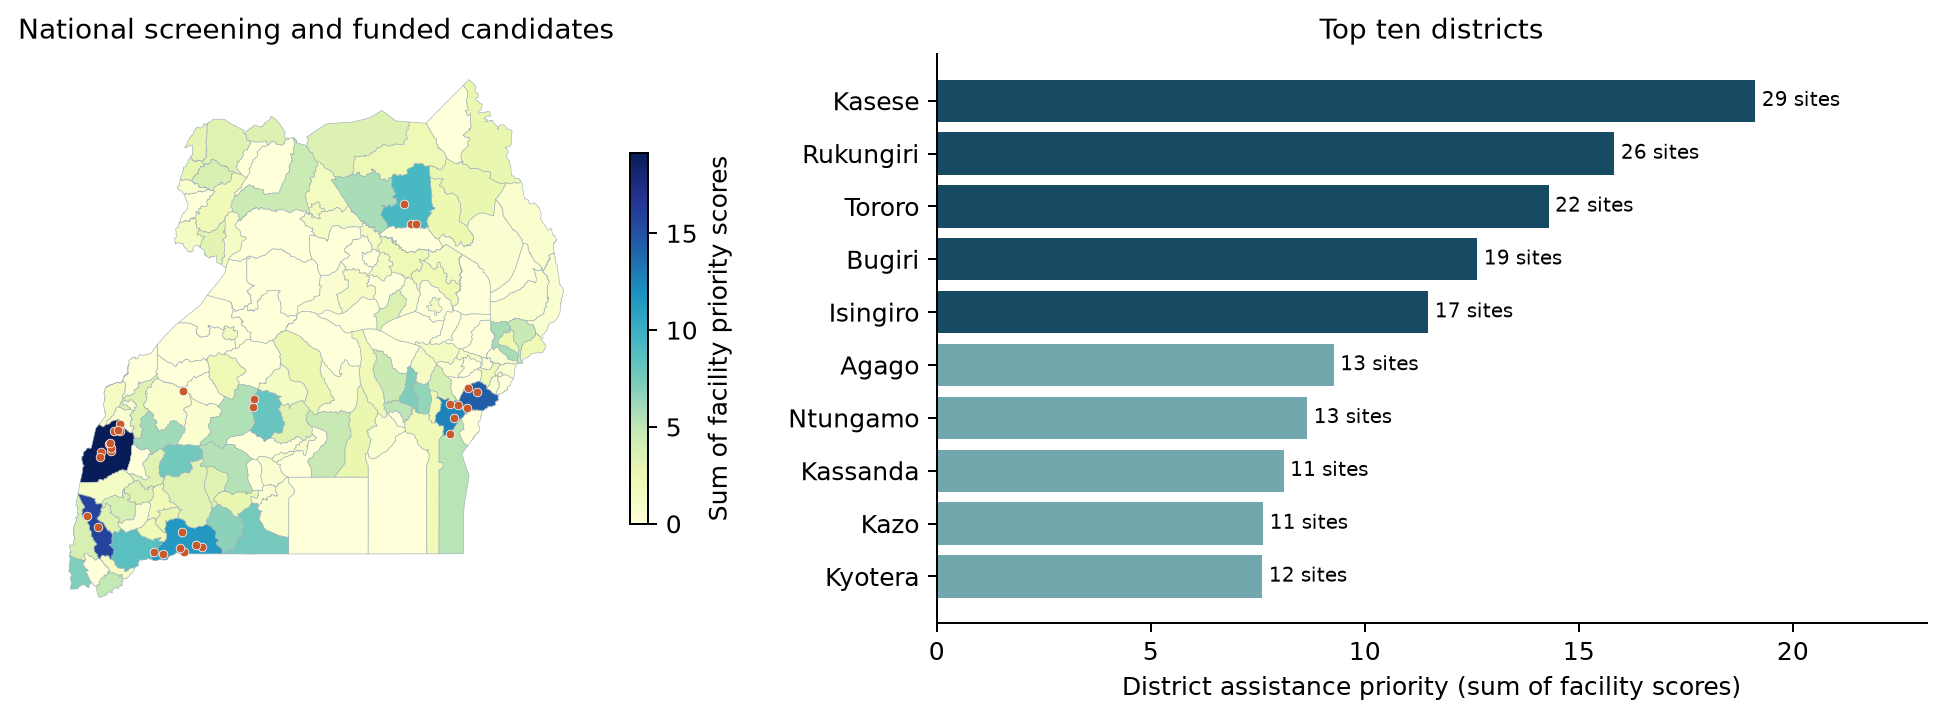

In [4]:
ranking = pd.read_csv(ROOT/'outputs/district_ranking.csv')
display(ranking.head(15).round(3))
from src.make_figures import run as make_figures
make_figures()
display(Image(filename=str(ROOT/'outputs/figures/national_priorities.png')))

## 5. Budget and named conditional awards

Official cost comparator: the Ministry's 2025 HFSE announcement reports USD 5 million for 250 facilities (USD 20,000 average). Assume critical-service packages of USD 20,000 for HC II and USD 40,000 for HC III, with a 25% uplift beyond 5 km from distribution. These are planning assumptions, not tender prices or full-facility energy guarantees.

Reserve one facility in each top-five district, commit at least USD 240,000 of the installation ceiling to remote sites nationally, then fill by score within the top five and finally elsewhere if necessary. Cap each district at ten facilities. Maintenance and audit reserves remain protected. The report discusses the two large HC III full-load profiles separately.

In [5]:
funded = pd.read_csv(ROOT/'outputs/funded_facilities.csv')
display(pd.read_csv(ROOT/'outputs/budget.csv'))
display(pd.read_csv(ROOT/'outputs/district_budget.csv').round(2))
display(funded[['id','FACILITY_N','LEVEL','district','daily_kwh','line_km','installation_usd','catchment_5km']].round(2))
assert len(funded)==32 and funded.id.is_unique
assert funded.imputed_fields.isna().all()
assert pd.read_csv(ROOT/'outputs/budget.csv').usd.sum()==1_000_000

,item,usd
0,Installed critical-service systems,790000
1,"Audits, design and duplicate-funding checks",50000
2,Five-year maintenance reserve,100000
3,Contingency and unallocated installation balance,60000


,district,facilities,installation_usd,modelled_people,remote_facilities,hc_iii,installation_usd_per_modelled_person
0,Agago,3,125000,19030.86,3,2,6.57
1,Bugiri,4,80000,39594.58,0,0,2.02
2,Isingiro,7,165000,67702.73,1,1,2.44
3,Kasese,10,200000,116292.83,0,0,1.72
4,Kassanda,2,50000,17965.95,2,0,2.78
5,Kyenjojo,1,50000,14970.40,1,1,3.34
6,Rukungiri,2,40000,17802.34,0,0,2.25
7,Tororo,3,80000,30412.28,0,1,2.63


,id,FACILITY_N,LEVEL,district,daily_kwh,line_km,installation_usd,catchment_5km
0,2817,Kotomor HC III,HC III,Agago,26.67,8.0,50000,7862.37
1,2826,Lapirin HC III,HC III,Agago,133.97,7.0,50000,5619.38
2,2819,Onudapet HC II,HC II,Agago,8.32,10.0,25000,5549.10
3,1605,Nkaiza HC II,HC II,Bugiri,12.21,4.0,20000,10968.63
4,1581,Nsango HC II,HC II,Bugiri,12.21,4.0,20000,6597.94
5,1563,Maziriga HC II,HC II,Bugiri,12.21,1.0,20000,9030.25
6,1575,Nakigundu HC II,HC II,Bugiri,8.32,1.0,20000,12997.75
7,4298,Kakamba (Isingiro) HC II,HC II,Isingiro,12.21,6.0,25000,6723.28
8,4294,Mbaare HC III,HC III,Isingiro,26.67,0.0,40000,12415.55
9,4297,Kagaaga HC II,HC II,Isingiro,8.32,4.0,20000,9495.28


## 6. Cost, preference and catchment sensitivity

Cost scenarios re-run awards rather than changing the unit price of a fixed list. Weight scenarios test the stability of district priorities. The catchment-radius comparison keeps the selected facilities fixed. A value-first comparison removes the remote reservation while retaining the top-five seed, geographic cap and budget rules; it is a heuristic comparison, not a globally optimal health-benefit frontier.

,cost_change_pct,facilities,installation_usd,modelled_people,contingency_usd,district_allocation
0,-20,42,800000,425922,50000,Agago: 4; Bugiri: 6; Isingiro: 9; Kasese: 10; ...
1,0,32,790000,323772,60000,Agago: 3; Bugiri: 4; Isingiro: 7; Kasese: 10; ...
2,20,26,798000,266006,52000,Agago: 2; Bugiri: 3; Isingiro: 5; Kasese: 8; K...
3,40,22,777000,230026,73000,Agago: 1; Bugiri: 3; Isingiro: 4; Kasese: 7; K...


,policy,weights,top_five
0,Baseline,"{""population"": 0.45, ""clinical_energy"": 0.25, ...",Kasese; Rukungiri; Tororo; Bugiri; Isingiro
1,More population,"{""population"": 0.65, ""clinical_energy"": 0.15, ...",Kasese; Rukungiri; Tororo; Bugiri; Isingiro
2,More equity,"{""population"": 0.25, ""clinical_energy"": 0.15, ...",Kasese; Rukungiri; Tororo; Bugiri; Isingiro


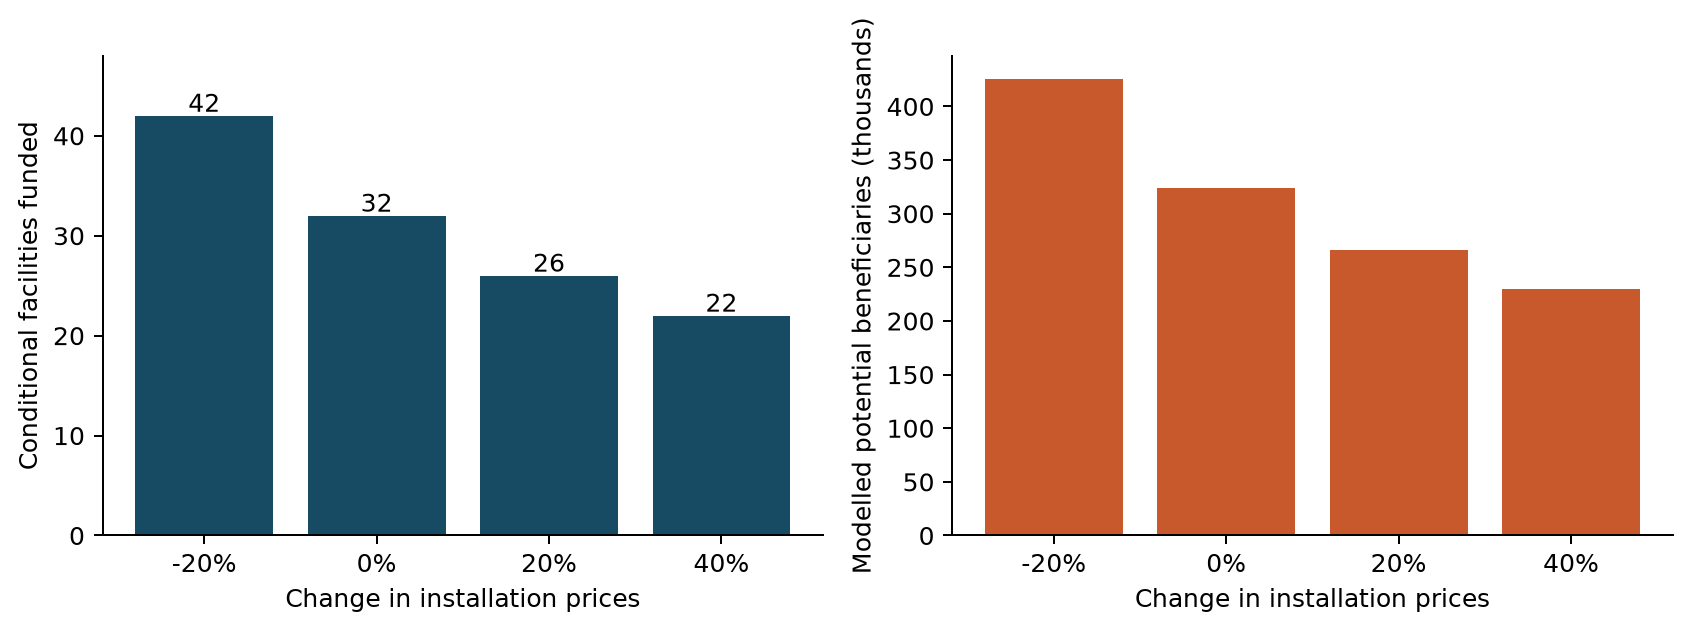

,radius_km,modelled_people
0,3,246627.0
1,5,323772.0
2,10,348521.0


Equity plan: 32 sites; 323772 modelled residents; 7 remote sites
Value-first plan: 40 sites; 475246 modelled residents; 0 remote sites


In [6]:
display(pd.read_csv(ROOT/'outputs/cost_sensitivity.csv'))
display(pd.read_csv(ROOT/'outputs/weight_sensitivity.csv'))
display(Image(filename=str(ROOT/'outputs/figures/cost_sensitivity.png')))
display(pd.DataFrame({'radius_km':[3,5,10], 'modelled_people':[summary['modelled_people_3km'],summary['modelled_people_5km'],summary['modelled_people_10km']]}).round())
print('Equity plan:',summary['funded_facilities'],'sites;',round(summary['modelled_people_5km']),'modelled residents;',summary['remote_facilities_funded'],'remote sites')
print('Value-first plan:',summary['value_first_facilities'],'sites;',round(summary['value_first_modelled_people']),'modelled residents;',summary['value_first_remote_facilities'],'remote sites')

## 7. Evidence limits and sources

Population estimates are potential beneficiaries of improved power at their assigned facility, not verified patients, households electrified, or avoided deaths. Historical status, mixed data vintages, unmeasured outages, road access, equipment and staffing can change recommendations. Before procurement, reconcile named sites against current MoH and donor projects, verify loads and reliability, obtain connection offers and bids, and agree maintenance responsibilities.

- [Energy Access Explorer](https://www.energyaccessexplorer.org/) and public layer metadata in `data/raw/uganda-datasets.json`.
- [EAE: Data and Methods (Mentis et al. 2019)](https://www.wri.org/research/energy-access-explorer-data-and-methods).
- [Uganda healthcare demand method (Sinclair-Lecaros et al. 2023)](https://www.wri.org/research/gis-assessment-electricity-health-care-uganda).
- [Official MoH HFSE cost comparator, 31 July 2025](https://health.go.ug/ministry-of-health-to-solarize-250-health-facilities-under-the-health-facility-solar-electrification-hfse-project/).

Original data-owner citations and licences are preserved in the EAE catalogue. `docs/sources.json` records attribution and cost interpretation.